# Stage 1d: Preprocess FakeNewsNet (PolitiFact + GossipCop)

**Stage:** 1 (preprocessing) · **Runs on:** Kaggle and locally

| | |
|---|---|
| Input | `politifact_fake.csv`, `politifact_real.csv`, `gossipcop_fake.csv`, `gossipcop_real.csv` (KaiDMML version) |
| Output | `fakenewsnet_cleaned.csv` (the only file saved; tables and plots are shown in this notebook) |
| Used for | Task A classification, Task C clustering |

The files have no label column: the label comes from the **file name**. The text is the
**headline** (`title`). `news_url`, `id` and `tweet_ids` are dropped; the URL reveals the publisher.
GossipCop balancing happens in Stage 2, so the full cleaned data is saved here.

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("01d")

misinfo_utils | stage 01d | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\01_preprocess


In [2]:
MIN_WORDS = 3   # headlines are short

## 1. Load the four files

In [3]:
parts = []
for site in ["politifact", "gossipcop"]:
    for kind, label in [("fake", 1), ("real", 0)]:
        part = pd.read_csv(mu.find_file(f"{site}_{kind}.csv"))
        print(f"{site}_{kind}.csv  {len(part):>6,} rows | columns: {list(part.columns)}")
        parts.append(pd.DataFrame({"text": part["title"], "label": label, "sub_source": site}))

# Fixed file order above -> stable row_ids
raw = pd.concat(parts, ignore_index=True)
raw.insert(0, "row_id", mu.make_row_ids(len(raw), "fakenewsnet"))
print("Total:", f"{len(raw):,}", "rows")

politifact_fake.csv     432 rows | columns: ['id', 'news_url', 'title', 'tweet_ids']
politifact_real.csv     624 rows | columns: ['id', 'news_url', 'title', 'tweet_ids']
gossipcop_fake.csv   5,323 rows | columns: ['id', 'news_url', 'title', 'tweet_ids']
gossipcop_real.csv  16,817 rows | columns: ['id', 'news_url', 'title', 'tweet_ids']
Total: 23,196 rows


## 2. Checks before cleaning

* **Balance:** GossipCop has far more real than fake headlines (balanced in Stage 2).
* **Conflicts:** some headlines appear in both a fake and a real file. These are removed in cleaning.

In [4]:
balance = raw.groupby(["sub_source", "label"]).size().unstack().rename(columns=mu.LABEL_NAMES)
balance["% misleading"] = (100 * balance["misleading"] / balance.sum(axis=1)).round(1)
display(balance)

# How many labels does each (normalised) headline have? More than 1 = conflict
labels_per_headline = raw.assign(key=raw["text"].map(mu.dedup_key)).groupby("key")["label"].transform("nunique")
print("Rows whose headline appears with BOTH labels:", int((labels_per_headline > 1).sum()))

label,reliable,misleading,% misleading
sub_source,,,
gossipcop,16817,5323,24.0
politifact,624,432,40.9


Rows whose headline appears with BOTH labels: 372


## 3. Clean and remove duplicates

In [5]:
fnn_clean, log = mu.clean_and_deduplicate(raw, MIN_WORDS, target_col="label")
fnn_clean = mu.to_clean_schema(fnn_clean, "fakenewsnet")
pd.Series(log, name="rows").to_frame()

,rows
loaded,23196
after_missing_target,23196
after_empty_text,23196
after_min_length,22641
after_conflict_removal,22345
after_dedup,21221


label,reliable,misleading,% misleading
sub_source,,,
gossipcop,15572,4700,23.2
politifact,534,415,43.7


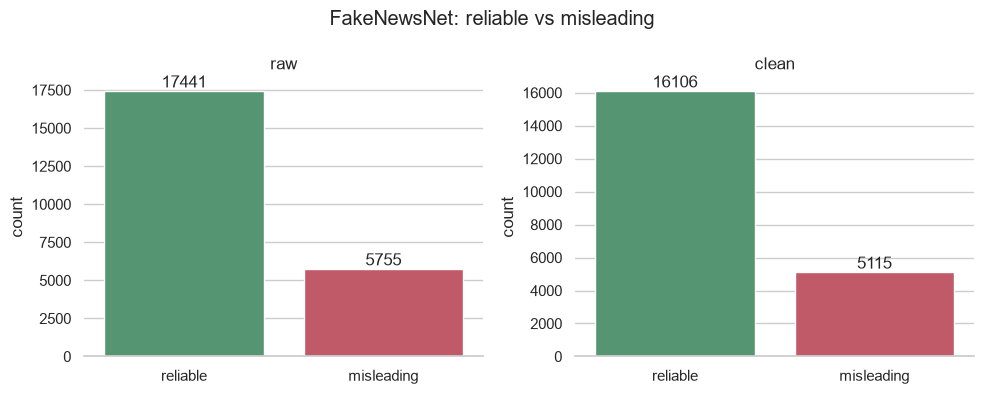

In [6]:
after = fnn_clean.groupby(["sub_source", "label"]).size().unstack().rename(columns=mu.LABEL_NAMES)
after["% misleading"] = (100 * after["misleading"] / after.sum(axis=1)).round(1)
display(after)

mu.plot_label_counts({"raw": raw, "clean": fnn_clean}, "FakeNewsNet: reliable vs misleading")

## 4. Save

In [7]:
mu.save_clean_dataset(fnn_clean, "fakenewsnet")
fnn_clean.head()

Saved 21,221 rows -> D:\misinfo-project\outputs\01_preprocess\fakenewsnet_cleaned.csv


,row_id,text,label,score,source_dataset,sub_source,n_words,had_url
0,fakenewsnet_000000,BREAKING: First NFL Team Declares Bankruptcy Over Kneeling Thugs,1,<NA>,fakenewsnet,politifact,9,False
1,fakenewsnet_000001,Court Orders Obama To Pay $400 Million In Restitution,1,<NA>,fakenewsnet,politifact,9,False
2,fakenewsnet_000002,UPDATE: Second Roy Moore Accuser Works For Michelle Obama Right NOW -,1,<NA>,fakenewsnet,politifact,12,False
3,fakenewsnet_000003,Oscar Pistorius Attempts To Commit Suicide,1,<NA>,fakenewsnet,politifact,6,False
4,fakenewsnet_000004,Trump Votes For Death Penalty For Being Gay,1,<NA>,fakenewsnet,politifact,8,False


**Next stage:** `02_merge_and_split` reads this file. On Kaggle, save this notebook with
**Save Version → Save & Run All**, then add it as an input to `02_merge_and_split`.